In [1]:
import sys, os, warnings, subprocess
subprocess.run(["pip", "install", ".", "--quiet"], check=True,
               cwd="/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales")
warnings.simplefilter("ignore", UserWarning)

import numpy as np
import scipy as sp
import pygam

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

%matplotlib inline
plt.rcParams.update({
    'font.size':         8,
    'figure.dpi':        300,
    'svg.fonttype':      'none',
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Roboto'],
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])

from src.notebook import load_notebook_data
from src.timescales import (create_ints_dataframe_custom_grouping, convert_data_dict,
                             average_data_dict_converted, compute_deflections)
from src.plotting import create_sydnor_sa_colormap
from src.gams import (fit_all_panels, apply_region_mask, get_series_colors, get_draw_order,
                      style_ax, compute_deriv_sa_corr, bootstrap_deriv_sa_corr)

  DEPRECATION: Building 'src' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'src'. Discussion can be found at https://github.com/pypa/pip/issues/6334


# Load data

In [2]:
dataset       = 'HCP-D' # 'HCP-D' 'PNC'
which_modality = 'FMRI'

if dataset == 'HCP-D':
    output_type   = 'timescale_auc_zero_crossing_bp-0.01-0.08hz'
elif dataset == 'PNC':
    output_type   = 'timescale_auc_zero_crossing'
    # output_type   = 'timescale_zero_crossing'
    # output_type   = 'timescale_zero_crossing_robust_nc2'
    # output_type   = 'timescale_zero_crossing_robust_nc3'

notebook_data = load_notebook_data(dataset=dataset, which_modality=which_modality,
                                   output_type=output_type, use_resids=True)

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-D
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/processed
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       652 subjects

	Initialized Timescales for dataset: HCP-D
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded 2760 scans from scan_registry_HCP-D.csv


Loading metric_tsnr: 100%|██████████| 2760/2760 [00:00<00:00, 7530.92it/s]


2760
timescale_auc_zero_crossing_bp-0.01-0.08hz


Loading timescale_auc_zero_crossing_bp-0.01-0.08hz: 100%|██████████| 2760/2760 [00:00<00:00, 8348.38it/s]


2760


Loading timescale_auc_zero_crossing_bp-0.01-0.08hz_resids: 100%|██████████| 2760/2760 [00:00<00:00, 8348.19it/s]

2760
Number of subjects: 552


In [3]:
timescales_processor = notebook_data['timescales_processor']
data_dict            = notebook_data['data_dict']

if dataset == 'HCP-D':
    sa_axis_file = os.path.join(timescales_processor.output_dir, 'data', 'supporting_data',
                                'schaefer400-7_sa-axis.npy')
elif dataset in ('PNC', 'NKI', 'HBN'):
    sa_axis_file = os.path.join(timescales_processor.output_dir, 'data', 'supporting_data',
                                'schaefer400-17_sa-axis.npy')
sa_axis = sp.stats.rankdata(np.load(sa_axis_file))

nas_scratch_dir = f'/mnt/lindenmp_nas/lindenmp/work/figure_scratch/intrinsic_neural_timescales/{dataset}'
os.makedirs(nas_scratch_dir, exist_ok=True)

# Prepare data

In [4]:
timescales_processor.match_registry_to_behavior()
df_behavior = timescales_processor.df_behavior_matched.copy()

if dataset == 'HCP-D':
    rest_scan = 'task-Rest'
    task_scan = 'tfMRICARITPA'
    # task_scan = 'tfMRIGUESSINGPA'
elif dataset == 'PNC':
    rest_scan = 'rest'
    task_scan = 'frac2back'

data_dict_tsnr      = notebook_data['data_dict_tsnr']
data_dict_converted = convert_data_dict(data_dict, timescales_processor.scan_registry)
data_dict_centiles  = convert_data_dict(data_dict, timescales_processor.scan_registry,
                                        brain_map=sa_axis)
data_dict_converted = average_data_dict_converted(data_dict_converted, average_all_rest=True)
data_dict_centiles  = average_data_dict_converted(data_dict_centiles,  average_all_rest=True)
df_tsnr             = create_ints_dataframe_custom_grouping(data_dict_tsnr, average_all_rest=True)

rfMRIREST1PA (552, 400)
rfMRIREST2PA (552, 400)
tfMRICARITPA (552, 400)
tfMRIEMOTIONPA (552, 400)
tfMRIGUESSINGPA (552, 400)
rfMRIREST1PA (552, 10)
rfMRIREST2PA (552, 10)
tfMRICARITPA (552, 10)
tfMRIEMOTIONPA (552, 10)
tfMRIGUESSINGPA (552, 10)


# Fit GAMs

In [5]:
df_behavior

,sex,age,meanFD,nih_fluidcogcomp_unadjusted,nih_crycogcomp_unadjusted,nih_dccs_ageadjusted,nih_flanker_ageadjusted,tbx_ls,tbx_reading_score,tbx_vocab_theta,...,bas_fs,bas_rr,premed_score,senseek_score,persev_score,pss_totalscore,fearanx_tscore,wellbeing_tscore,sensation_tscore,carit_nogo_acc
subject_id,,,,,,,,,,,,,,,,,,,,,
HCD2939275V1MR,0.0,16.250000,0.097079,125.0,108.0,108.0,96.0,20.0,106.0,5.837,...,4.0,8.0,8.0,12.0,13.0,999.0,54.0,56.0,999.0,0.833333
HCD0051825V1MR,0.0,18.166667,0.108911,120.0,117.0,111.0,101.0,18.0,109.0,8.778,...,15.0,17.0,5.0,14.0,11.0,999.0,NaN,999.0,999.0,0.750000
HCD1168245V1MR,1.0,18.500000,0.157230,118.0,94.0,111.0,85.0,16.0,97.0,2.170,...,13.0,20.0,4.0,16.0,10.0,999.0,NaN,999.0,999.0,0.875000
HCD1057337V1MR,1.0,19.416667,0.081428,121.0,122.0,89.0,102.0,21.0,117.0,8.973,...,11.0,17.0,4.0,10.0,12.0,999.0,NaN,999.0,999.0,0.958333
HCD1701338V1MR,1.0,20.833333,0.108502,125.0,111.0,107.0,97.0,23.0,116.0,4.948,...,14.0,19.0,6.0,9.0,11.0,999.0,NaN,999.0,999.0,0.791667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
HCD0855562V1MR,0.0,11.083333,0.186895,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.0,9.0,7.0,12.0,16.0,NaN,NaN,NaN,NaN,0.833333
HCD2462654V1MR,1.0,15.166667,0.110215,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.0,11.0,4.0,12.0,11.0,NaN,NaN,NaN,NaN,0.750000
HCD0906250V1MR,0.0,9.000000,0.177872,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.0,12.0,7.0,10.0,13.0,NaN,NaN,NaN,NaN,0.500000


In [6]:
# GAM parameters
n_splines   = 4
lam         = 0.1
nuisance_regression = False
absolute = True

# Region-level data
rest_full = data_dict_converted[rest_scan]
try:
    task_full = data_dict_converted[task_scan]
except (KeyError, TypeError):
    task_full = data_dict_converted[rest_scan]
n_subs = task_full.shape[0]
n_regions = task_full.shape[1]

# Covariate data
age      = df_behavior['age'].values
if dataset == 'HCP-D':
    nuisance = np.concat((df_behavior[['sex', 'meanFD']].values,
                        np.nanmean(rest_full, axis=1)[:, np.newaxis]), axis=1) # add mean rest INTs as covariate
elif dataset == 'PNC':
    nuisance = np.concat((df_behavior[['sex', 'meanFD_rest']].values,
                        np.nanmean(rest_full, axis=1)[:, np.newaxis]), axis=1) # add mean rest INTs as covariate
else:
    nuisance = None
age_grid = np.linspace(age.min(), age.max(), 200)

deflection_full = compute_deflections(rest_full, task_full,
                                      nuisance_regression=nuisance_regression,
                                      standardize=False, absolute=absolute)
# deflection_full = np.zeros(task_full.shape)
# for i in range(n_regions):
#     deflection_full[:, i] = compute_deflections(rest_full[:, i], task_full[:, i],
#                                                 nuisance_regression=nuisance_regression,
#                                                 standardize=False, absolute=absolute)

# Decile-binned data
rest_dec = data_dict_centiles[rest_scan]
try:
    task_dec = data_dict_centiles[task_scan]
except (KeyError, TypeError):
    task_dec = data_dict_centiles[rest_scan]

deflection_dec = compute_deflections(rest_dec, task_dec,
                                     nuisance_regression=nuisance_regression,
                                     standardize=False, absolute=absolute)
# deflection_dec = np.zeros((n_subs, 10))
# for i in range(10):
#     deflection_dec[:, i] = compute_deflections(rest_dec[:, i], task_dec[:, i],
#                                                 nuisance_regression=nuisance_regression,
#                                                 standardize=False, absolute=absolute)

n_deciles     = rest_dec.shape[1]
results_dec   = fit_all_panels(age, rest_dec, task_dec, deflection_dec, age_grid,
                               n_splines=n_splines, lam=lam, demean=True, show_ci=False,
                               nuisance=nuisance)

cmap          = create_sydnor_sa_colormap()
series_colors = get_series_colors('decile', n_deciles, cmap)
draw_order    = get_draw_order('decile', n_deciles)

# Region-level fits
apply_tsnr_mask = False  # set True to exclude low-tSNR regions

if apply_tsnr_mask:
    region_mask = (df_tsnr[task_scan] < np.quantile(df_tsnr[task_scan], q=0.1)).values
else:
    region_mask = None

rest_reg, task_reg, defl_reg, sa_axis_reg = apply_region_mask(
    region_mask, rest_full, task_full, deflection_full, sa_axis=sa_axis)

results_reg = fit_all_panels(age, rest_reg, task_reg, defl_reg, age_grid,
                             n_splines=n_splines, lam=lam, demean=True, show_ci=False,
                             nuisance=nuisance)
print(f'Decile shape: {deflection_dec.shape}  |  Regional shape: {defl_reg.shape}   |  Nusiance shape: {nuisance.shape}')

Decile shape: (552, 10)  |  Regional shape: (552, 400)   |  Nusiance shape: (552, 3)


In [7]:
boot_curves = bootstrap_deriv_sa_corr(
    defl_reg, age, sa_axis_reg, age_grid,
    n_splines=n_splines, lam=lam, demean=True, nuisance=nuisance,
    n_boot=500, method='pearson', random_state=42)

r_ci_lo = np.nanpercentile(boot_curves, 2.5,  axis=0)
r_ci_hi = np.nanpercentile(boot_curves, 97.5, axis=0)
print(f'Bootstrap done. 95% CI at age midpoint: [{r_ci_lo[100]:.3f}, {r_ci_hi[100]:.3f}]')

Bootstrap:   0%|          | 0/500 [00:00<?, ?it/s]

Bootstrap done. 95% CI at age midpoint: [-0.046, 0.296]


/home/lindenmp/anaconda3/envs/intrinsic_neural_timescales/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


# Figure 4

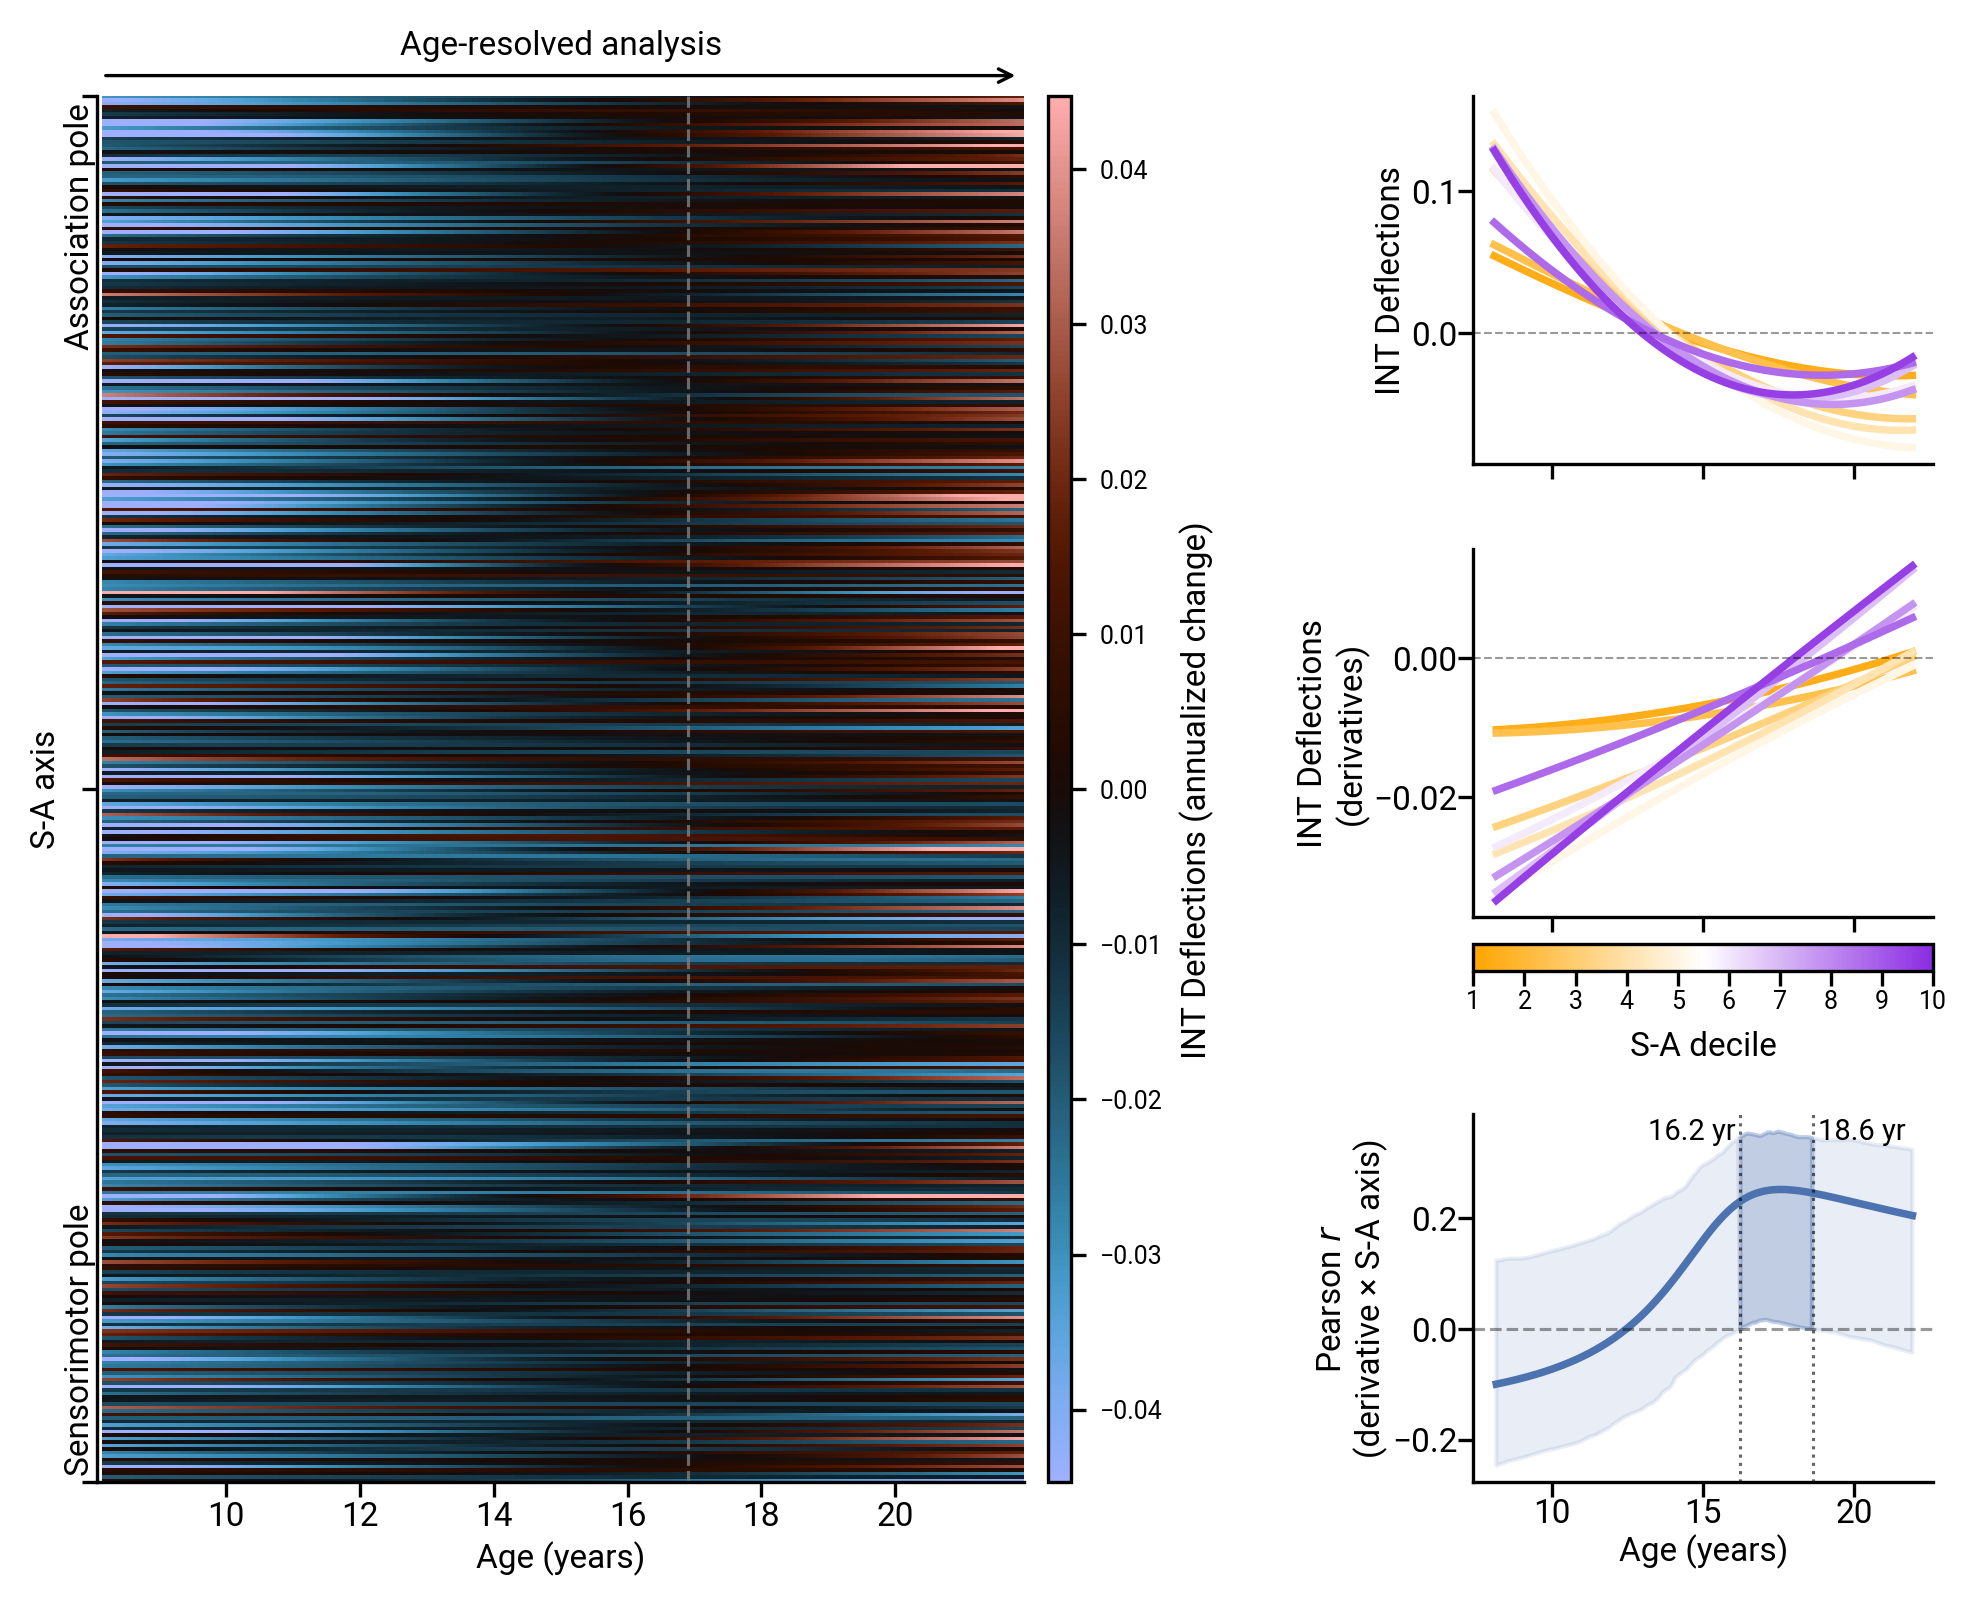

In [8]:
# --- Parameters ---
signal_type = 'deflection'  # 'rest', 'task', or 'deflection'
plot_level  = 'region'      # 'region' or 'decile'
# ------------------

_signal_labels = {'rest': 'REST INTs', 'task': 'Task INTs', 'deflection': 'INT Deflections'}
lw = 1.8

# Heatmap data
_reg_deriv = results_reg[signal_type]['deriv']

if plot_level == 'region':
    sort_idx     = np.argsort(sa_axis_reg)
    deriv_sorted = _reg_deriv[sort_idx]
    ylabel       = 'S-A axis'
    bottom_label = 'Sensorimotor pole'
    top_label    = 'Association pole'
else:
    deriv_sorted = results_dec[signal_type]['deriv']
    ylabel       = 'S-A axis decile'
    bottom_label = 'Sensorimotor'
    top_label    = 'Association'

n_rows = deriv_sorted.shape[0]
vmax   = np.nanpercentile(np.abs(deriv_sorted), 98)

crossing_ages = []
for i in range(n_rows):
    row = deriv_sorted[i, :]
    for t in range(len(row) - 1):
        if row[t] < 0 and row[t + 1] >= 0:
            frac = -row[t] / (row[t + 1] - row[t])
            crossing_ages.append(age_grid[t] + frac * (age_grid[t + 1] - age_grid[t]))
            break
mean_cross_age = np.mean(crossing_ages) if crossing_ages else None

r_vals = compute_deriv_sa_corr(_reg_deriv, sa_axis_reg, method='pearson')

# Figure layout
fig      = plt.figure(figsize=(9, 6), dpi=300)
gs_outer = GridSpec(1, 2, figure=fig, width_ratios=[1, 1], wspace=0.15)

# Left column: heatmap | narrow vertical colorbar
gs_left   = GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_outer[0],
                                    width_ratios=[1, 0.025], wspace=0.05)
ax_heat   = fig.add_subplot(gs_left[0])
ax_cbar_h = fig.add_subplot(gs_left[1])

# Right column: pred / deriv / SA-decile cbar / Pearson r
gs_right   = GridSpecFromSubplotSpec(4, 1, subplot_spec=gs_outer[1],
                                     height_ratios=[1, 1, 0.075, 1], hspace=0.3)
ax0        = fig.add_subplot(gs_right[0])
ax1        = fig.add_subplot(gs_right[1], sharex=ax0)
ax_cbar_sa = fig.add_subplot(gs_right[2])
ax2        = fig.add_subplot(gs_right[3], sharex=ax0)

# Heatmap
im = ax_heat.imshow(
    deriv_sorted, aspect='auto', origin='lower',
    extent=[age_grid[0], age_grid[-1], 0, n_rows],
    cmap='berlin', vmin=-vmax, vmax=vmax, interpolation='nearest',
)
if mean_cross_age is not None:
    ax_heat.axvline(mean_cross_age, color='gray', linestyle='--', lw=0.75, alpha=0.8)

ax_heat.set_xlabel('Age (years)', fontsize=8, labelpad=2)
ax_heat.set_ylabel(ylabel, fontsize=8, labelpad=4)
if plot_level == 'region':
    ax_heat.set_yticks([0, n_rows // 2, n_rows])
    ax_heat.set_yticklabels(['', '', ''], fontsize=8)
else:
    ax_heat.set_yticks(np.arange(n_rows) + 0.5)
    ax_heat.set_yticklabels([str(i + 1) for i in range(n_rows)], fontsize=8)
ax_heat.tick_params(labelsize=8, pad=1)

ax_heat.annotate(top_label,    xy=(age_grid[0], n_rows), xytext=(-8, -1.5), rotation=90,
                 textcoords='offset points', fontsize=8, va='top',    annotation_clip=False)
ax_heat.annotate(bottom_label, xy=(age_grid[0], 0),      xytext=(-8,  1.5), rotation=90,
                 textcoords='offset points', fontsize=8, va='bottom', annotation_clip=False)
ax_heat.annotate('', xy=(age_grid[-1], n_rows + n_rows * 0.015),
                 xytext=(age_grid[0],  n_rows + n_rows * 0.015),
                 arrowprops=dict(arrowstyle='->', color='k', lw=0.8), annotation_clip=False)
ax_heat.text((age_grid[0] + age_grid[-1]) / 2, n_rows + n_rows * 0.025,
             'Age-resolved analysis', ha='center', va='bottom', fontsize=8, clip_on=False)

cb_h = fig.colorbar(im, cax=ax_cbar_h, orientation='vertical')
cb_h.set_label(f'{_signal_labels[signal_type]} (annualized change)', fontsize=8)
cb_h.ax.yaxis.set_label_position('right')
cb_h.ax.tick_params(labelsize=6)

# Line plots
for i in draw_order:
    ax0.plot(age_grid, results_dec[signal_type]['pred'][i], color=series_colors[i], lw=lw)
style_ax(ax0, 'Age (years)', f'{_signal_labels[signal_type]}', None, demean=True)
ax0.set_xlabel('')
ax0.set_box_aspect(0.8)
plt.setp(ax0.get_xticklabels(), visible=False)

for i in draw_order:
    ax1.plot(age_grid, results_dec[signal_type]['deriv'][i], color=series_colors[i], lw=lw)
style_ax(ax1, 'Age (years)', f'{_signal_labels[signal_type]}\n(derivatives)', None, demean=True)
ax1.set_xlabel('')
ax1.set_box_aspect(0.8)
plt.setp(ax1.get_xticklabels(), visible=False)

# Reposition SA decile colorbar to match ax1 actual rendered width (after box_aspect)
fig.canvas.draw()
renderer    = fig.canvas.get_renderer()
bbox1       = ax1.get_window_extent(renderer=renderer)
fig_w_px, fig_h_px = fig.get_size_inches() * fig.dpi
x0_f   = bbox1.x0 / fig_w_px
y0_f   = bbox1.y0 / fig_h_px
w_f    = bbox1.width / fig_w_px
cbar_height = 0.015
pad         = 0.015
ax_cbar_sa.set_position([x0_f, y0_f - pad - cbar_height, w_f, cbar_height])

norm_sa = mcolors.Normalize(vmin=1, vmax=n_deciles)
sm_sa   = plt.cm.ScalarMappable(cmap=cmap, norm=norm_sa)
sm_sa.set_array([])
cb_sa = fig.colorbar(sm_sa, cax=ax_cbar_sa, orientation='horizontal')
cb_sa.set_label('S-A decile', fontsize=8)
cb_sa.set_ticks(list(range(1, n_deciles + 1)))
cb_sa.ax.tick_params(labelsize=6, pad=1)

ax2.fill_between(age_grid, r_ci_lo, r_ci_hi,
                 where=(r_ci_lo > 0), color='#4C72B0', alpha=0.35, interpolate=True)
ax2.fill_between(age_grid, r_ci_lo, r_ci_hi,
                 where=(r_ci_lo <= 0), color='#4C72B0', alpha=0.12, interpolate=True)
ax2.plot(age_grid, r_vals, color='#4C72B0', lw=lw)
ax2.axhline(0, color='k', lw=0.75, ls='--', alpha=0.4)

# Annotate ages where bootstrap CI lower bound crosses zero
ci_positive = r_ci_lo > 0
_diffs = np.diff(ci_positive.astype(int))
for idx in np.where(_diffs)[0]:
    lo0, lo1 = r_ci_lo[idx], r_ci_lo[idx + 1]
    cross_age = age_grid[idx] + (-lo0 / (lo1 - lo0)) * (age_grid[idx + 1] - age_grid[idx])
    ax2.axvline(cross_age, color='k', lw=0.75, ls=':', alpha=0.6)
    if _diffs[idx] > 0:  # entering positive region: label on left
        ha, xpos = 'right', cross_age - 0.15
    else:                # exiting positive region: label on right
        ha, xpos = 'left', cross_age + 0.15
    ax2.text(xpos, 0.99, f'{cross_age:.1f} yr',
             ha=ha, va='top', fontsize=7, color='k',
             transform=ax2.get_xaxis_transform())

ax2.set_xlabel('Age (years)', fontsize=8, labelpad=1)
ax2.set_ylabel(f'Pearson $r$\n(derivative \u00d7 S-A axis)', fontsize=8, labelpad=1)
ax2.tick_params(labelsize=8, pad=0.25)
ax2.set_box_aspect(0.8)
ax2.spines[['top', 'right']].set_visible(False)
# if mean_cross_age is not None:
#     ax2.axvline(mean_cross_age, color='gray', linestyle='--', lw=0.75, alpha=0.8)

fig.savefig(os.path.join(nas_scratch_dir, 'fig4_combined.png'),
            dpi=1000, bbox_inches='tight', transparent=True)
plt.show()

In [9]:
# Save regional and decile-level GAM outputs for cross-notebook analysis (nct_analysis_fig5.ipynb)
from src.gams import compute_partial_r2_age

gam_out_dir = os.path.join(timescales_processor.output_dir, 'results', dataset, 'gam')
os.makedirs(gam_out_dir, exist_ok=True)

save_dict = {
    'age_grid':    age_grid,
    'sa_axis_reg': sa_axis_reg,
    'task_scan':   task_scan,
    'n_deciles':   n_deciles,
}
for sig in ('rest', 'task', 'deflection'):
    # Regional (n_regions, n_grid)
    save_dict[f'{sig}_deriv']     = results_reg[sig]['deriv']
    save_dict[f'{sig}_pred']      = results_reg[sig]['pred']
    # Decile (n_deciles, n_grid)
    save_dict[f'{sig}_deriv_dec'] = results_dec[sig]['deriv']
    save_dict[f'{sig}_pred_dec']  = results_dec[sig]['pred']
    # Partial R² of age smooth per region
    save_dict[f'{sig}_partial_r2'] = compute_partial_r2_age(
        {'rest': rest_reg, 'task': task_reg, 'deflection': defl_reg}[sig],
        age, results_reg[sig]['gams'], nuisance=nuisance, demean=True
    )

# r(derivative × SA axis) explicitly for deflection
save_dict['r_vals']  = compute_deriv_sa_corr(
    results_reg['deflection']['deriv'], sa_axis_reg, method='pearson')
save_dict['r_ci_lo'] = r_ci_lo
save_dict['r_ci_hi'] = r_ci_hi

out_file = os.path.join(gam_out_dir, f'{dataset}_regional_gam_results.npy')
np.save(out_file, save_dict)
print(f'Saved GAM results -> {out_file}')
for sig in ('rest', 'task', 'deflection'):
    r2 = save_dict[f'{sig}_partial_r2']
    print(f"  {sig}_partial_r2: shape={r2.shape}, mean={np.nanmean(r2):.4f}, max={np.nanmax(r2):.4f}")
print(f"  deflection_deriv : {save_dict['deflection_deriv'].shape}")
print(f"  age_grid         : {save_dict['age_grid'].shape}")

Saved GAM results -> /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales/results/HCP-D/gam/HCP-D_regional_gam_results.npy
  rest_partial_r2: shape=(400,), mean=0.0076, max=0.0479
  task_partial_r2: shape=(400,), mean=0.0099, max=0.0502
  deflection_partial_r2: shape=(400,), mean=0.0077, max=0.0334
  deflection_deriv : (400, 200)
  age_grid         : (200,)
